# Bước C1 (phần so sánh) - tinh chỉnh 5 lõi của mô hình chung Sequential Forecast (LSTM, GRU, Transformer, S4D, Mamba), mỗi lõi 8 cấu hình (2 độ sâu x 2 mức dung lượng x 2 learning rate), 1 hạt giống (111), chỉ validation, loại sớm hai vòng: vòng 1 mọi cấu hình tới epoch 15 (lịch cosine T_max 30), vòng 2 cấu hình được giữ chạy tiếp tới epoch 30.
# Bảng 40 cấu hình (39 lần C1 + LSTM 1 lớp, cùng tham số, learning rate 10^-3 = B* hạt giống 111), chọn cấu hình chạy
 vòng 2 theo luật ghi sẵn, rồi khi đủ vòng 2 chọn hai cấu hình mỗi lõi cho C2 theo NSE trung vị validation, đánh đổi độ
 chính xác - chi phí, lệnh sinh notebook C2. Cùng một tệp chạy hai lần: sau vòng 1 (in danh sách notebook _Cont cần
 chạy, chưa chọn C2) và sau vòng 2 (chọn C2).
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 5.2 (lưới, cách chọn C2),
 5.3 (nhiễu hạt giống), 6.1 (chỉ NSE trung vị validation dùng để chọn), 7 (dòng C1, C2).
# Notebook Kaggle "11_C1_LamaHCEExt_Compare": Accelerator = None (CPU), Internet = Off, Persistence = Files only,
# Environment = Pin to original environment. Add Input:
   - Output 39 notebook 10_C1_Tune_<cấu hình>_<lr> (vòng 1); lần chạy sau vòng 2: cấu hình đã chạy notebook _Cont thì
     gắn Output notebook _Cont thay cho phiên 1 (thư mục run trong đó đủ 30 epoch; gắn cả hai thì giữ bản nhiều epoch
     hơn, nhưng tổng Input tối đa 50);
   - Output notebook huấn luyện B* hạt giống 111 (08_B3_LamaHCEExt_Train_P10S12_Seed111).
 Không cần GPU, không cần thư viện NeuralHydrology: chỉ đọc config.yml, validation_metrics.csv, output.log của thư mục run.
 Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Tìm Output 40 run, kiểm sha256, giao thức, cấu hình
   Phần 2 - Validation theo epoch, thời gian từng epoch, bảng 40 cấu hình
   Phần 3 - Vòng 1: chọn cấu hình chạy tiếp tới epoch 30, kiểm vòng 2 đã đủ chưa
   Phần 4 - Chọn cấu hình C2 mỗi lõi, so với nhiễu hạt giống (khi đủ vòng 2)
   Phần 5 - Hình
   Phần 6 - Lưu kết quả, danh sách _Cont hoặc lệnh sinh notebook C2, môi trường

cấu hình,notebook,Version,thư mục run,model,hidden_size,epochs config,patience,data_on_gpu,số model_epoch,trạng thái,phiên,số tham số,mốc,commit,config đúng
lstm_L1_x1_lr1e-3,B*,1,B3_P10S12_SeqLSTM_Q_seed111_3110_054455,sequential_forecast_lstm,128,30,30,True,30,-,-,84865.0000,-,2ccaa14,ĐẠT
lstm_L1_x1_lr5e-4,10-c1-tune-lstm-l1-x1-lr5e-4-cont,1,C1_lstm_L1_x1_lr5e-4_seed111_0211_143812,sequential_forecast,128,15,30,True,30,xong,2,84865.0000,84865.0000,db6dc1f,ĐẠT
lstm_L1_x3_lr1e-3,10-c1-tune-lstm-l1-x3-lr1e-3-cont,1,C1_lstm_L1_x3_lr1e-3_seed111_0311_124839,sequential_forecast,235,15,30,True,30,xong,2,254888.0000,84865.0000,db6dc1f,ĐẠT
lstm_L1_x3_lr5e-4,10-c1-tune-lstm-l1-x3-lr5e-4-cont,1,C1_lstm_L1_x3_lr5e-4_seed111_0311_124837,sequential_forecast,235,15,30,True,30,xong,2,254888.0000,84865.0000,db6dc1f,ĐẠT
lstm_L2_x1_lr1e-3,10-c1-tune-lstm-l2-x1-lr1e-3-cont,1,C1_lstm_L2_x1_lr1e-3_seed111_0311_103130,sequential_forecast,77,15,30,True,30,xong,2,84106.0000,84865.0000,db6dc1f,ĐẠT
lstm_L2_x1_lr5e-4,10-c1-tune-lstm-l2-x1-lr5e-4,1,C1_lstm_L2_x1_lr5e-4_seed111_0311_102930,sequential_forecast,77,15,30,True,15,xong vòng 1,1,84106.0000,84865.0000,db6dc1f,ĐẠT
lstm_L2_x3_lr1e-3,10-c1-tune-lstm-l2-x3-lr1e-3-cont,1,C1_lstm_L2_x3_lr1e-3_seed111_0311_024505,sequential_forecast,139,15,30,True,30,xong,2,253800.0000,84865.0000,db6dc1f,ĐẠT
lstm_L2_x3_lr5e-4,10-c1-tune-lstm-l2-x3-lr5e-4-cont,1,C1_lstm_L2_x3_lr5e-4_seed111_0311_024250,sequential_forecast,139,15,30,True,30,xong,2,253800.0000,84865.0000,db6dc1f,ĐẠT
gru_L1_x1_lr1e-3,10-c1-tune-gru-l1-x1-lr1e-3,1,C1_gru_L1_x1_lr1e-3_seed111_0411_010148,sequential_forecast,150,15,30,True,15,xong vòng 1,1,84743.0000,84865.0000,db6dc1f,ĐẠT
gru_L1_x1_lr5e-4,10-c1-tune-gru-l1-x1-lr5e-4,1,C1_gru_L1_x1_lr5e-4_seed111_0311_051940,sequential_forecast,150,15,30,True,15,xong vòng 1,1,84743.0000,84865.0000,db6dc1f,ĐẠT


Commit thư viện của B*: 2ccaa14 - C1 dùng lại B* hạt giống 111 khi B* chạy cùng mã bộ nạp với freeze-C (Pipeline Mục 5.2); khác commit thì đối chiếu ở báo cáo.


mục,giá trị,cần,đạt
Số cấu hình,40,40 (39 C1 + B*),ĐẠT
sha256 khớp manifest.csv,506 / 506 tệp,đủ,ĐẠT
"Trạng thái C1 khớp số epoch (15 = xong vòng 1, 30 = xong)","[(15, 'xong vòng 1'), (30, 'xong')]","[(15, 'xong vòng 1'), (30, 'xong')]",ĐẠT
"Config đúng cấu hình (lõi, độ sâu, lr, hạt giống)",40,40,ĐẠT
epochs config / early_stopping_patience / data_on_gpu (39 C1),"[(15, 30, True)]","[(15, 30, True)]",ĐẠT
epochs config / early_stopping_patience / data_on_gpu / số model_epoch (B*),"[30, 30, True, 30]","[30, 30, True, 30]",ĐẠT
Số model_epoch*.pt mỗi run,"[15, 30]",15 hoặc 30,ĐẠT
Mốc tham số chung của 39 C1,[84865.0],một giá trị,ĐẠT
Lệch tham số so với mức x mốc (C1),0.894%,<= 1%,ĐẠT
Commit thư viện 39 C1,['db6dc1f'],một commit (freeze-C),ĐẠT


=> Đạt. Chạy Phần 2.


cấu hình,lõi,độ sâu,mức,lr,số tham số,số epoch,epoch chọn,NSE val,KGE val,NSE val <= 15,NSE val epoch cuối,phút huấn luyện/epoch,phút validation/epoch,giờ GPU đã chạy,giờ GPU,GPU MiB,hạng trong lõi
lstm_L1_x1_lr1e-3,lstm,1,x1,lr1e-3,84865,30,23,0.7612,0.7850,0.7584,0.7525,3.3742,0.9521,2.1882,2.1882,-,5
lstm_L1_x1_lr5e-4,lstm,1,x1,lr5e-4,84865,30,13,0.7677,0.7891,0.7677,0.7586,3.2934,0.9396,2.1893,2.1893,3053.0000,2
lstm_L1_x3_lr1e-3,lstm,1,x3,lr1e-3,254888,30,26,0.7624,0.7976,0.7602,0.7595,6.8288,1.4280,4.1824,4.1824,2117.0000,4
lstm_L1_x3_lr5e-4,lstm,1,x3,lr5e-4,254888,30,11,0.7639,0.7817,0.7639,0.7561,7.0483,1.4584,4.2960,4.2960,2117.0000,3
lstm_L2_x1_lr1e-3,lstm,2,x1,lr1e-3,84106,30,24,0.7679,0.8028,0.7623,0.7677,3.2909,0.8121,2.1094,2.1094,2381.0000,1
lstm_L2_x1_lr5e-4,lstm,2,x1,lr5e-4,84106,15,14,0.7475,0.7704,0.7475,0.7378,3.1404,0.7818,1.0069,2.0137,2381.0000,8
lstm_L2_x3_lr1e-3,lstm,2,x3,lr1e-3,253800,30,16,0.7581,0.7946,0.7555,0.7544,19.6947,8.9075,14.3748,14.3748,3557.0000,6
lstm_L2_x3_lr5e-4,lstm,2,x3,lr5e-4,253800,30,12,0.7579,0.7936,0.7579,0.7490,20.1830,8.9804,14.6310,14.6310,3557.0000,7
gru_L1_x1_lr1e-3,gru,1,x1,lr1e-3,84743,15,9,0.7524,0.7616,0.7524,0.7423,5.3402,1.8117,1.8152,3.6305,3177.0000,5
gru_L1_x1_lr5e-4,gru,1,x1,lr5e-4,84743,15,15,0.7510,0.7527,0.7510,0.7510,5.1411,1.7323,1.7474,3.4948,3177.0000,6


mục,giá trị,cần,đạt
Validation đủ lưu vực mỗi epoch,[451],[451],ĐẠT
Epoch chọn = saved_epoch trong summary.json (39 C1),39 / 39,bằng nhau,ĐẠT
Đọc được thời gian mọi epoch từ output.log,960,960,ĐẠT


=> Đạt. Chạy Phần 3.


lõi,cấu hình,NSE val <= 15,cách tốt nhất lõi,cách / nhiễu hạt giống,giữ,lý do,số epoch,giờ vòng 2 ước,tăng cần để vượt
lstm,lstm_L1_x1_lr5e-4,0.7677,0.0000,0.0000,có,trong nhiễu + tốt nhất x1,30,0.0000,-
lstm,lstm_L1_x3_lr5e-4,0.7639,0.0038,0.4791,có,trong nhiễu,30,0.0000,-
lstm,lstm_L2_x1_lr1e-3,0.7623,0.0054,0.6846,có,trong nhiễu,30,0.0000,-
lstm,lstm_L1_x3_lr1e-3,0.7602,0.0075,0.9514,có,trong nhiễu,30,0.0000,-
lstm,lstm_L1_x1_lr1e-3,0.7584,0.0093,1.1747,mở rộng,cần +0.0094 <= tăng lớn nhất 0.0175,30,0.0000,0.0094
lstm,lstm_L2_x3_lr5e-4,0.7579,0.0098,1.2380,mở rộng,cần +0.0099 <= tăng lớn nhất 0.0175,30,0.0000,0.0099
lstm,lstm_L2_x3_lr1e-3,0.7555,0.0122,1.5475,mở rộng,cần +0.0124 <= tăng lớn nhất 0.0175,30,0.0000,0.0124
lstm,lstm_L2_x1_lr5e-4,0.7475,0.0202,2.5557,,,15,0.0000,0.0203
gru,gru_L2_x1_lr1e-3,0.7659,0.0000,0.0000,có,trong nhiễu + tốt nhất x1,30,0.0000,-
gru,gru_L1_x3_lr1e-3,0.7586,0.0073,0.9244,có,trong nhiễu,30,0.0000,-


16 cấu hình giữ theo luật đã có 30 epoch. Spearman giữa NSE val <= 15 và NSE val 30 epoch của chúng: 0.81; tăng sau epoch 15: trung vị 0.0024, lớn nhất 0.0175 (mamba_L4_x3_lr1e-3). Mở rộng 8 cấu hình: ['lstm_L1_x1_lr1e-3', 'lstm_L2_x3_lr5e-4', 'lstm_L2_x3_lr1e-3', 'gru_L2_x1_lr5e-4', 'gru_L2_x3_lr5e-4', 'transformer_L2_x3_lr5e-4', 's4d_L4_x3_lr5e-4', 's4d_L2_x1_lr5e-4'].
Vòng 2 đủ: 24 cấu hình được giữ (kể cả mở rộng) có 30 epoch.
=> Đạt. Chạy Phần 4.


lõi,quy tắc,cấu hình,NSE val,cấu hình đứng sau,cách đứng sau,cách / nhiễu hạt giống,epoch chọn,epoch chọn = 30,hiệu NSE với B* (trung vị lưu vực),lưu vực hơn B*,giờ C2 ước,cần _Cont
lstm,tốt nhất mức x1 + tốt nhất cả 8,lstm_L2_x1_lr1e-3,0.7679,lstm_L1_x1_lr5e-4,0.0001,0.0178,24,,-0.0015,213 / 451,2.8155,
gru,tốt nhất mức x1 + tốt nhất cả 8,gru_L2_x1_lr1e-3,0.7707,gru_L2_x1_lr5e-4,0.0068,0.8545,20,,-0.0017,212 / 451,2.9428,
transformer,tốt nhất mức x1,transformer_L2_x1_lr1e-3,0.7358,-,-,-,24,,-0.0207,101 / 451,8.0933,
transformer,tốt nhất cả 8,transformer_L2_x3_lr5e-4,0.7408,transformer_L2_x1_lr1e-3,0.0050,0.6359,24,,-0.0239,97 / 451,10.9621,có
s4d,tốt nhất mức x1,s4d_L4_x1_lr1e-3,0.7377,s4d_L2_x1_lr1e-3,0.0046,0.5776,14,,-0.0307,78 / 451,8.0244,
s4d,tốt nhất cả 8,s4d_L4_x3_lr1e-3,0.7410,s4d_L4_x1_lr1e-3,0.0033,0.4212,20,,-0.0233,89 / 451,15.9831,có
mamba,tốt nhất mức x1,mamba_L2_x1_lr1e-3,0.7633,mamba_L4_x1_lr1e-3,0.0046,0.5796,19,,-0.0053,185 / 451,6.7204,
mamba,tốt nhất cả 8,mamba_L4_x3_lr1e-3,0.7728,mamba_L2_x3_lr1e-3,0.0079,0.9988,28,,0.0004,227 / 451,16.2075,có


7 / 8 lựa chọn cách cấu hình đứng sau dưới 1 lần nhiễu hạt giống: thứ hạng giữa chúng chưa chắc với 1 hạt giống, ghi rõ khi kết luận (Pipeline Mục 5.2).
Tổng giờ C2 ước: 215 giờ; cần phiên 2: ['transformer_L2_x3_lr5e-4', 's4d_L4_x3_lr1e-3', 'mamba_L4_x3_lr1e-3']
=> Đạt. Chạy Phần 5.


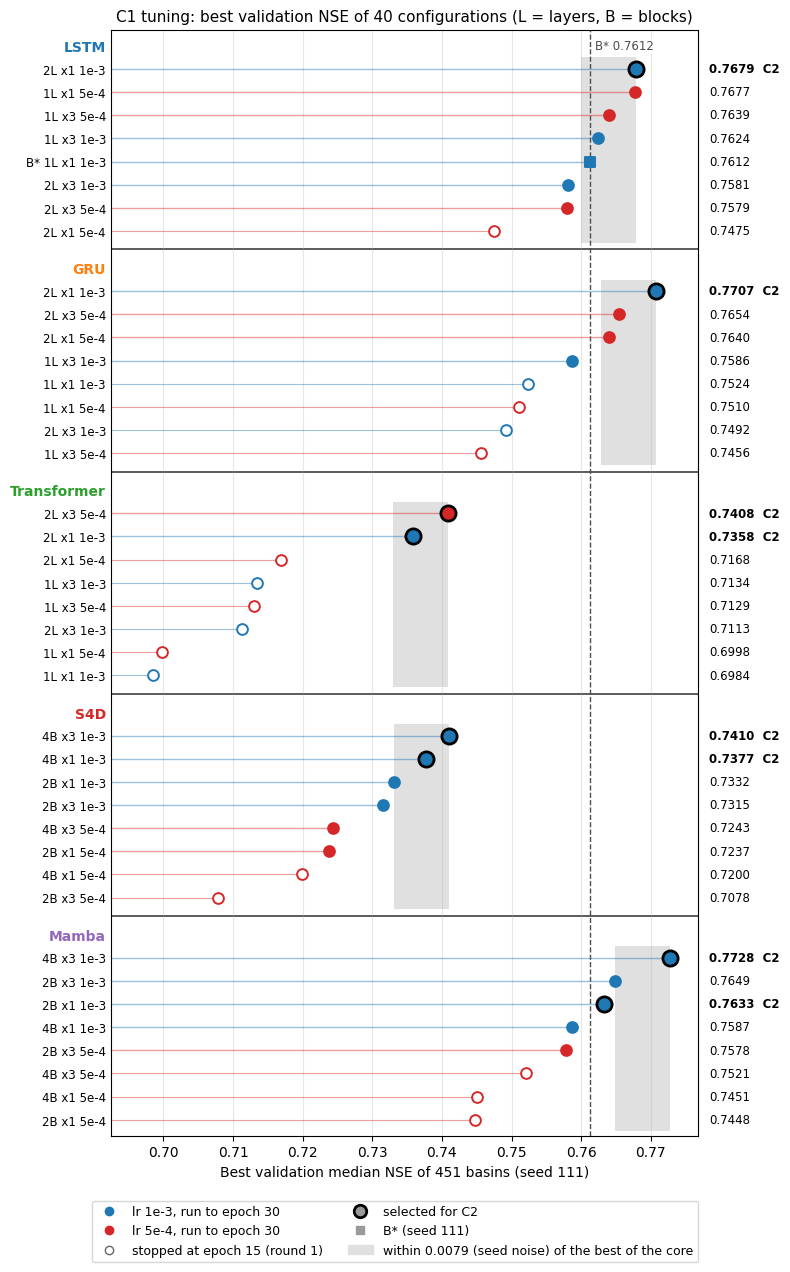

Hình: NSE trung vị 451 lưu vực của kỳ validation ở epoch tốt nhất, 40 cấu hình C1 (hạt giống 111), mỗi lõi một khối, trong khối xếp từ cao xuống; số ở cột phải, "C2" là cấu hình chọn chạy chính thức. Màu là learning rate; chấm đặc là cấu hình chạy tới epoch 30 (16 giữ theo luật + 8 mở rộng), chấm rỗng là cấu hình dừng ở epoch 15; ô vuông và đường gạch đứng là B* (0,7612). Dải xám là khoảng 0,0079 (độ lệch chuẩn giữa 3 hạt giống) dưới cấu hình tốt nhất của lõi: cấu hình trong dải chưa phân biệt được với cấu hình tốt nhất khi chỉ có 1 hạt giống. Cao nhất cả lưới Mamba 4B x3 1e-3 (0,7728).


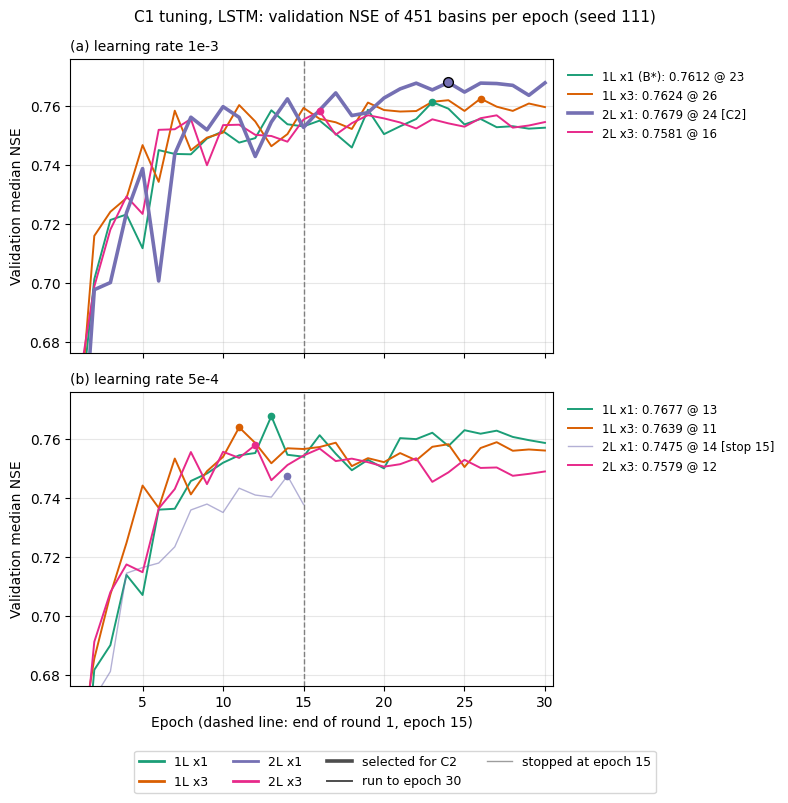

Hình: LSTM: NSE trung vị validation theo epoch của 8 cấu hình C1 (hạt giống 111); ô (a) learning rate 10^-3, ô (b) 5x10^-4; màu là độ sâu và mức dung lượng, nét đậm là cấu hình chọn C2 (LSTM 2L x1 1e-3), nét nhạt mảnh dừng ở epoch 15 là cấu hình bị loại ở vòng 1; chấm là epoch tốt nhất, chú giải ghi NSE @ epoch đó. Trục dọc từ 0,676; 9 điểm ở epoch 1-2 thấp hơn, nằm ngoài trục (nhỏ nhất 0,589). Đường dao động mạnh giữa các epoch (một hạt giống), nên NSE tốt nhất của mỗi cấu hình là đỉnh của một đường nhiễu.


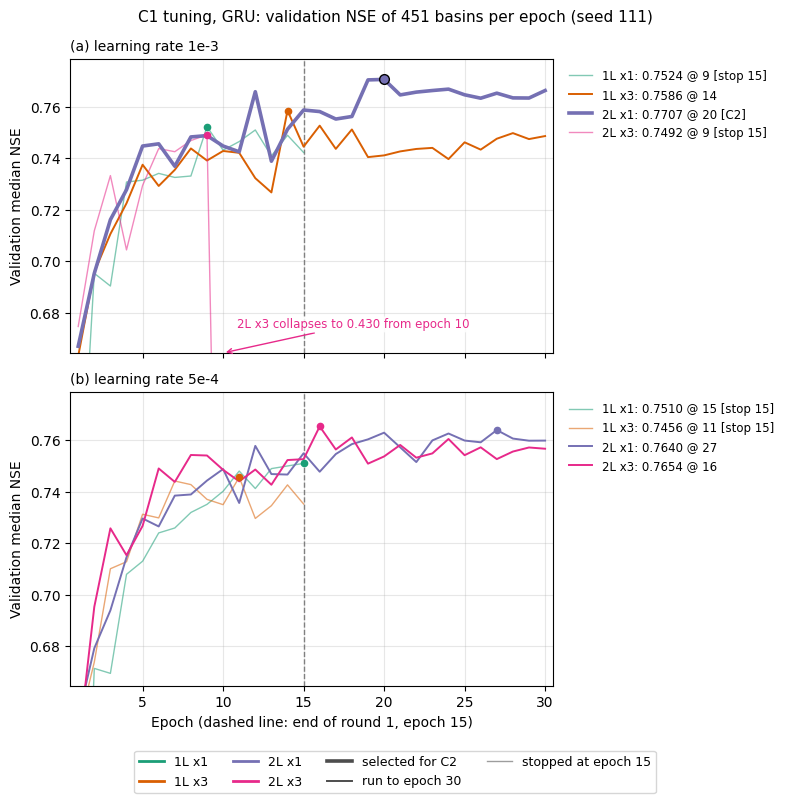

Hình: GRU: NSE trung vị validation theo epoch của 8 cấu hình C1 (hạt giống 111); ô (a) learning rate 10^-3, ô (b) 5x10^-4; màu là độ sâu và mức dung lượng, nét đậm là cấu hình chọn C2 (GRU 2L x1 1e-3), nét nhạt mảnh dừng ở epoch 15 là cấu hình bị loại ở vòng 1; chấm là epoch tốt nhất, chú giải ghi NSE @ epoch đó. Trục dọc từ 0,664; 6 điểm ở epoch 1-2 thấp hơn, nằm ngoài trục (nhỏ nhất 0,520); GRU 2L x3 1e-3 sụp xuống 0,430 và không hồi lại (ghi trong hình). Đường dao động mạnh giữa các epoch (một hạt giống), nên NSE tốt nhất của mỗi cấu hình là đỉnh của một đường nhiễu.


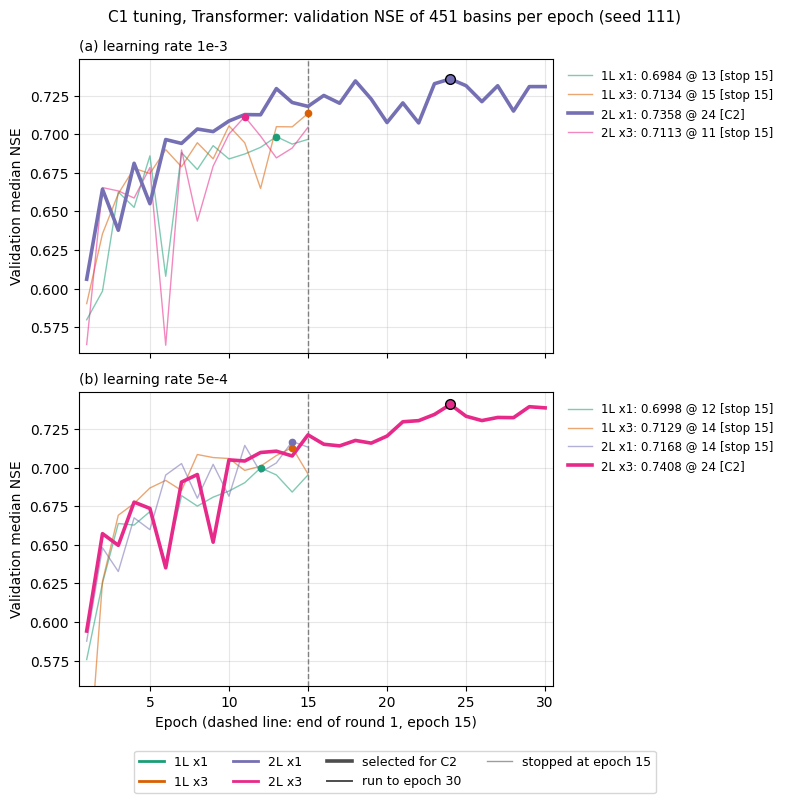

Hình: Transformer: NSE trung vị validation theo epoch của 8 cấu hình C1 (hạt giống 111); ô (a) learning rate 10^-3, ô (b) 5x10^-4; màu là độ sâu và mức dung lượng, nét đậm là cấu hình chọn C2 (Transformer 2L x1 1e-3, Transformer 2L x3 5e-4), nét nhạt mảnh dừng ở epoch 15 là cấu hình bị loại ở vòng 1; chấm là epoch tốt nhất, chú giải ghi NSE @ epoch đó. Trục dọc từ 0,558; 1 điểm ở epoch 1-2 thấp hơn, nằm ngoài trục (nhỏ nhất 0,486). Đường dao động mạnh giữa các epoch (một hạt giống), nên NSE tốt nhất của mỗi cấu hình là đỉnh của một đường nhiễu.


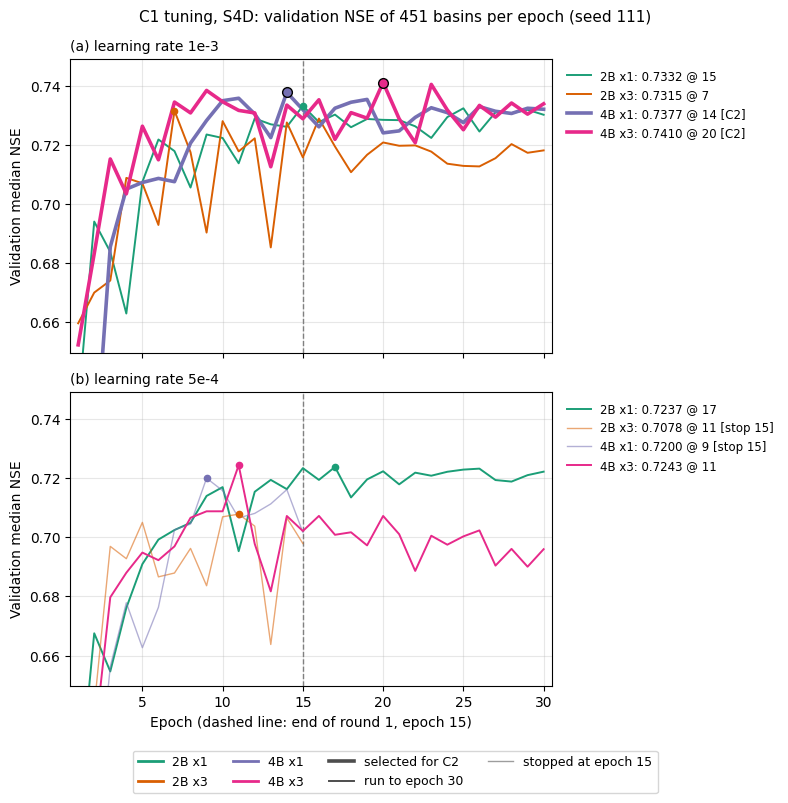

Hình: S4D: NSE trung vị validation theo epoch của 8 cấu hình C1 (hạt giống 111); ô (a) learning rate 10^-3, ô (b) 5x10^-4; màu là độ sâu và mức dung lượng, nét đậm là cấu hình chọn C2 (S4D 4B x1 1e-3, S4D 4B x3 1e-3), nét nhạt mảnh dừng ở epoch 15 là cấu hình bị loại ở vòng 1; chấm là epoch tốt nhất, chú giải ghi NSE @ epoch đó. Trục dọc từ 0,650; 10 điểm ở epoch 1-2 thấp hơn, nằm ngoài trục (nhỏ nhất 0,602). Đường dao động mạnh giữa các epoch (một hạt giống), nên NSE tốt nhất của mỗi cấu hình là đỉnh của một đường nhiễu.


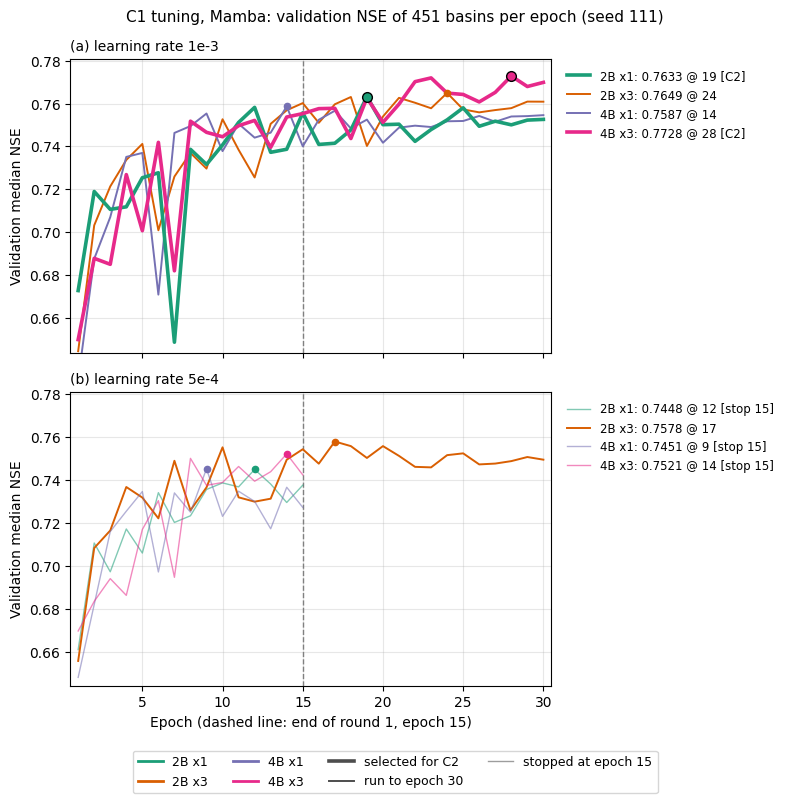

Hình: Mamba: NSE trung vị validation theo epoch của 8 cấu hình C1 (hạt giống 111); ô (a) learning rate 10^-3, ô (b) 5x10^-4; màu là độ sâu và mức dung lượng, nét đậm là cấu hình chọn C2 (Mamba 2B x1 1e-3, Mamba 4B x3 1e-3), nét nhạt mảnh dừng ở epoch 15 là cấu hình bị loại ở vòng 1; chấm là epoch tốt nhất, chú giải ghi NSE @ epoch đó. Trục dọc từ 0,644; 1 điểm ở epoch 1-2 thấp hơn, nằm ngoài trục (nhỏ nhất 0,631). Đường dao động mạnh giữa các epoch (một hạt giống), nên NSE tốt nhất của mỗi cấu hình là đỉnh của một đường nhiễu.


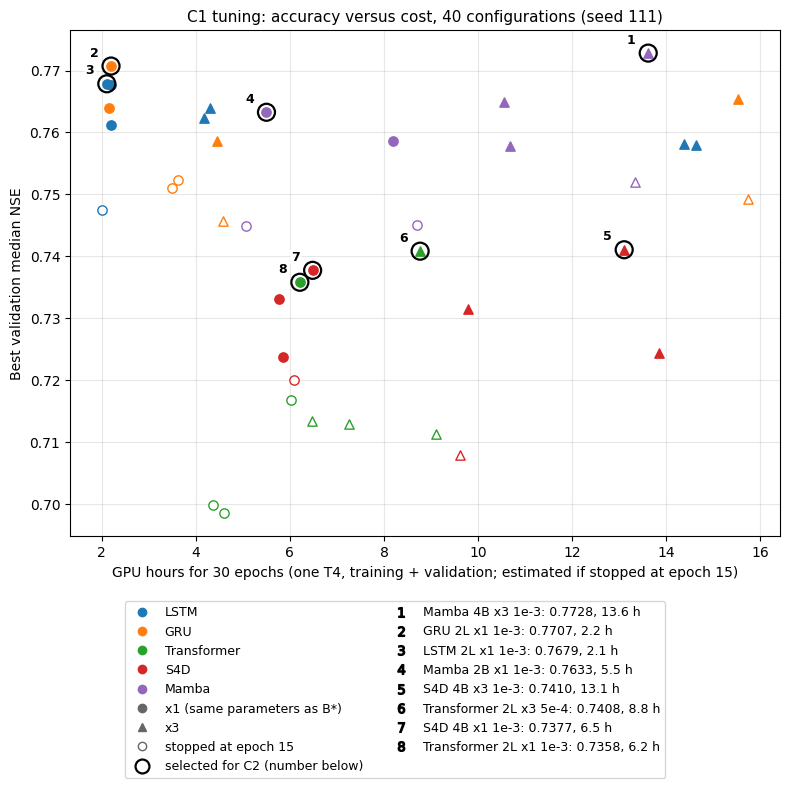

Hình: NSE trung vị validation tốt nhất theo số giờ GPU của 30 epoch (huấn luyện + validation trên một T4; cấu hình dừng ở epoch 15 ước theo tốc độ vòng 1); màu theo lõi, tròn là mức cùng tham số, tam giác là mức gấp 3, chấm rỗng là cấu hình dừng ở epoch 15, vòng đen đánh số là 8 cấu hình chọn C2 (tên, NSE và số giờ ở chú giải dưới hình). Rẻ nhất LSTM 2L x1 5e-4 (2,0 giờ), đắt nhất GRU 2L x3 1e-3 (15,7 giờ); số giờ phụ thuộc cài đặt cụ thể, không phải độ phức tạp thuật toán.


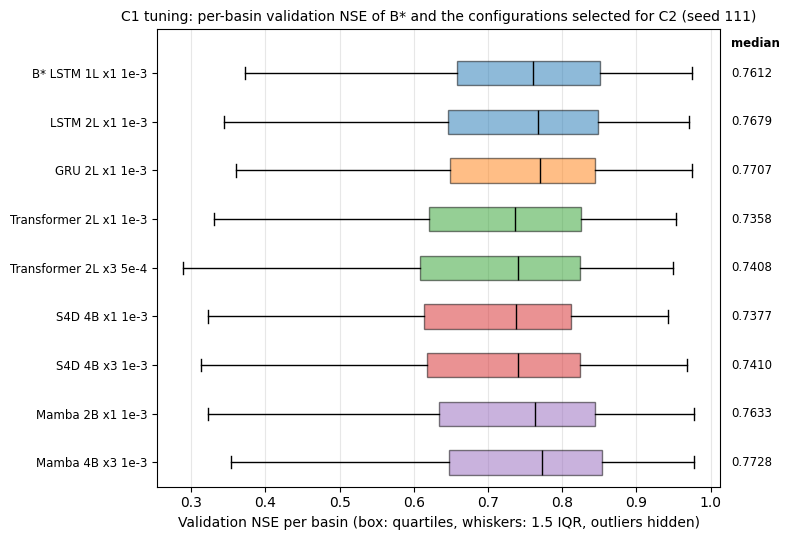

Hình: Phân bố NSE validation từng lưu vực (451 lưu vực, epoch tốt nhất của mỗi cấu hình, hạt giống 111) của B* và 8 cấu hình chọn C2; hộp là tứ phân vị, vạch đen là trung vị (số ở cột phải), râu dài tới 1,5 lần khoảng tứ phân vị, ẩn điểm ngoại lai; NSE dưới -1 tính là -1 (0 lưu vực nhiều nhất ở một cấu hình). Trung vị các cấu hình chênh nhau tối đa 0,0370, còn khoảng tứ phân vị mỗi cấu hình rộng 0,19-0,22: khác biệt giữa các cấu hình nhỏ so với khác biệt giữa các lưu vực.
=> Đạt. Chạy Phần 6.


tệp,KB,sha256
c1_compare/Figures/C1_Basin_Spread.png,113.1000,2841b809f557...
c1_compare/Figures/C1_Best_All.png,342.1000,d70ab77c0992...
c1_compare/Figures/C1_Cost.png,196.8000,9992451f0b2b...
c1_compare/Figures/C1_Curves_GRU.png,292.5000,2ec3dcea79bd...
c1_compare/Figures/C1_Curves_LSTM.png,299.3000,654877891243...
c1_compare/Figures/C1_Curves_Mamba.png,318.6000,69bb91c68ba1...
c1_compare/Figures/C1_Curves_S4D.png,323.1000,fbac8a336d27...
c1_compare/Figures/C1_Curves_Transformer.png,292.2000,de7f61f4b076...
c1_compare/c1_curves.csv,91.2000,fada91d37c1b...
c1_compare/c1_round1.csv,5.0000,8f697366cd8f...


Lệnh sinh notebook C2 (chạy ở máy, từ gốc repo):
  python Tools/C_Notebooks_Build.py c2 lstm_L2_x1_lr1e-3 gru_L2_x1_lr1e-3 transformer_L2_x1_lr1e-3 transformer_L2_x3_lr5e-4 s4d_L4_x1_lr1e-3 s4d_L4_x3_lr1e-3 mamba_L2_x1_lr1e-3 mamba_L4_x3_lr1e-3 --cont transformer_L2_x3_lr5e-4 s4d_L4_x3_lr1e-3 mamba_L4_x3_lr1e-3
=> Đạt. Xong notebook.


In [1]:
# %% Phần 1 - Tìm Output 40 run, kiểm sha256, giao thức, cấu hình
# Mỗi notebook huấn luyện có <x>_output/environment.json (run_dir tính từ /kaggle/working của notebook đó, commit thư
# viện) và manifest.csv (tệp chính kèm sha256). Nhận Output theo environment.json, không theo tên đường dẫn. Notebook C1
# (khuôn Tools/C_Notebook_Template.py) có thêm c_output/summary.json (trạng thái, số tham số, mốc). Gắn trùng cả phiên 1
# và _Cont của một cấu hình thì giữ bản nhiều epoch hơn. B* = run hạt giống 111 duy nhất không phải C1. Kiểm: đủ 40 cấu
# hình lưới, 39 C1 cùng commit thư viện (in commit của B*), sha256 khớp, config.yml đúng cấu hình và giao thức (C1:
# khóa epochs 15 của vòng 1 - chạy tiếp tới 30 bằng config phụ, config.yml của run giữ nguyên; B*: 30), số epoch đã
# huấn luyện 15 với trạng thái "xong vòng 1" hoặc 30 với "xong".
import hashlib
import json
import os
import platform
import re
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import HTML, display

IS_KAGGLE = Path("/kaggle/working").exists()
INPUT_ROOT = Path(os.environ.get("C1_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "c1_compare_input"))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("c1_compare_work")
OUT_DIR = WORK_DIR / "c1_compare"
CORE_DEPTHS = {"lstm": (1, 2), "gru": (1, 2), "transformer": (1, 2), "s4d": (2, 4), "mamba": (2, 4)}
LEVELS = (1, 3)
LRS = {"lr1e-3": 1e-3, "lr5e-4": 5e-4}
B_STAR_CONF = "lstm_L1_x1_lr1e-3"                 # cấu hình C1 lấy từ B* hạt giống 111 (Pipeline Mục 5.2)
SEED = 111
EPOCHS = 30
C1_CUT = 15           # C1 vòng 1 dừng ở epoch này (khuôn C, Pipeline Mục 5.2)
N_BASINS = 451
NOISE_SD = 0.0079     # độ lệch chuẩn NSE trung vị validation giữa 3 hạt giống B0 (ngưỡng B*, Pipeline Mục 5.3)
C1_RE = re.compile(r"^C1_(lstm|gru|transformer|s4d|mamba)_L(\d)_x([13])_(lr1e-3|lr5e-4)_seed(\d+)$")
VERSION_DEFAULT = 1                               # Version bản lưu chính thức của mỗi notebook huấn luyện
VERSIONS = {}                                     # tên cấu hình => Version, khi khác VERSION_DEFAULT
ENV_LIBS = ["numpy", "pandas", "matplotlib", "PyYAML"]
OUT_DIR.mkdir(parents=True, exist_ok=True)


def show(title, df, digits=4):
    # Bảng HTML: số thực làm tròn `digits` chữ số, ô trống hiện "-".
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=digits, na_rep="-"))


def show_checks(checks):
    # checks: [(mục, giá trị, cần, đạt)]; trả True nếu mọi dòng đạt.
    show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"}
                               for a, b, c, d in checks]))
    return all(c[3] for c in checks)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def read_metrics(path):
    # validation_metrics.csv của NeuralHydrology (tester.py _save_results): cột đầu là mã lưu vực => str(int).
    m = pd.read_csv(path, index_col=0)
    m.index = [str(int(b)) for b in m.index]
    return m


def grid_configs():
    # 40 cấu hình lưới theo thứ tự lõi, độ sâu, mức, learning rate.
    return [f"{c}_L{d}_x{lv}_{lr}" for c, ds in CORE_DEPTHS.items() for d in ds for lv in LEVELS for lr in LRS]


# (1) Output các notebook huấn luyện: nhận theo environment.json
found = []
for env_path in sorted(INPUT_ROOT.rglob("environment.json")):
    env = json.loads(env_path.read_text(encoding="utf-8"))
    if "run_dir" not in env:
        continue                                  # environment.json của notebook khác (không có thư mục run)
    root = env_path.parent.parent                 # thư mục tương ứng /kaggle/working của notebook đó
    run = root / env["run_dir"]
    cfg = yaml.safe_load((run / "config.yml").read_text(encoding="utf-8-sig"))
    summary_path = env_path.parent / "summary.json"
    found.append({"root": root, "out": env_path.parent, "run": run, "env": env, "cfg": cfg,
                  "summary": json.loads(summary_path.read_text(encoding="utf-8")) if summary_path.exists() else None,
                  "n_epochs": len(list(run.glob("model_epoch*.pt")))})

runs, dropped = {}, []
for f in found:
    m = C1_RE.match(f["cfg"]["experiment_name"])
    if m:
        conf = f"{m.group(1)}_L{m.group(2)}_x{m.group(3)}_{m.group(4)}"
    elif f["cfg"]["seed"] == SEED and f["cfg"]["experiment_name"].split("_")[0] not in ("C2", "TEST"):
        conf = B_STAR_CONF
    else:
        continue
    if conf in runs and conf != B_STAR_CONF:      # phiên 1 và _Cont cùng gắn => giữ bản nhiều epoch hơn
        keep, drop = sorted([runs[conf], f], key=lambda r: r["n_epochs"], reverse=True)
        runs[conf] = keep
        dropped.append(f"{conf}: bỏ {drop['out'].parent.name} ({drop['n_epochs']} epoch)")
    elif conf in runs:
        raise RuntimeError(f"Có 2 run được nhận là B* (hạt giống {SEED}, không phải C1): "
                           f"{runs[conf]['run'].name}, {f['run'].name} - chỉ gắn Output notebook B* hạt giống {SEED}")
    else:
        runs[conf] = f
GRID = grid_configs()
missing = [c for c in GRID if c not in runs]
if missing:
    raise RuntimeError(f"Thiếu {len(missing)} cấu hình: {missing} - kiểm Add Input")
for d in dropped:
    print("Gắn trùng:", d)

# (2) sha256 theo manifest.csv của từng Output
sha_rows = []
for conf in GRID:
    r = runs[conf]
    man = pd.read_csv(r["out"] / "manifest.csv")
    col = "file" if "file" in man else "tệp"     # Output B3 (B*) ghi cột "file", khuôn C ghi "tệp"
    bad = [rel for rel, dg in zip(man[col], man["sha256"]) if not (r["root"] / rel).exists() or sha256(r["root"] / rel) != dg]
    sha_rows.append({"cấu hình": conf, "tệp": len(man), "lệch": len(bad), "_bad": bad})

# (3) Bảng Output và kiểm config từng run
info_rows = []
for conf in GRID:
    r, cfg = runs[conf], runs[conf]["cfg"]
    core, depth, level, lr_tag = re.match(r"^(\w+?)_L(\d)_x(\d)_(lr.+)$", conf).groups()
    if conf == B_STAR_CONF:
        cfg_ok = cfg["seed"] == SEED and float(cfg["learning_rate"]) == LRS[lr_tag]
    else:
        cfg_ok = (cfg["model"] == "sequential_forecast" and cfg["sf_core"] == core and int(cfg["sf_layers"]) == int(depth)
                  and float(cfg["learning_rate"]) == LRS[lr_tag] and cfg["seed"] == SEED)
    s = r["summary"] or {}
    info_rows.append({"cấu hình": conf, "notebook": r["out"].parent.name if conf != B_STAR_CONF else "B*",
                      "Version": VERSIONS.get(conf, VERSION_DEFAULT), "thư mục run": r["run"].name,
                      "model": cfg["model"], "hidden_size": cfg["hidden_size"], "epochs config": cfg["epochs"],
                      "patience": cfg["early_stopping_patience"], "data_on_gpu": cfg.get("data_on_gpu"),
                      "số model_epoch": r["n_epochs"], "trạng thái": s.get("status", "-"), "phiên": s.get("session", "-"),
                      "số tham số": s.get("n_params"), "mốc": s.get("target_params"),
                      "commit": r["env"].get("neuralhydrology_commit", "?")[:7], "config đúng": cfg_ok})
INFO = pd.DataFrame(info_rows)
c1_info = INFO[INFO["cấu hình"] != B_STAR_CONF]
TARGET = int(c1_info["mốc"].iloc[0])
INFO.loc[INFO["cấu hình"] == B_STAR_CONF, "số tham số"] = TARGET   # B* = lõi LSTM 1 lớp cùng tham số = mốc
show(f"Output {len(INFO)} run (B* = {runs[B_STAR_CONF]['cfg']['experiment_name']})",
     INFO.assign(**{"config đúng": INFO["config đúng"].map({True: "ĐẠT", False: "KHÔNG"})}))
commits = sorted(set(c1_info["commit"]))
B_STAR_COMMIT = INFO.set_index("cấu hình").loc[B_STAR_CONF, "commit"]
B_STAR_PROTO = [v.item() if hasattr(v, "item") else v for v in
                INFO.set_index("cấu hình").loc[B_STAR_CONF, ["epochs config", "patience", "data_on_gpu", "số model_epoch"]]]
bad_sha = [r for r in sha_rows if r["lệch"]]
checks = [("Số cấu hình", len(INFO), "40 (39 C1 + B*)", len(INFO) == 40),
          ("sha256 khớp manifest.csv", f"{sum(r['tệp'] for r in sha_rows) - sum(r['lệch'] for r in sha_rows)} / "
           f"{sum(r['tệp'] for r in sha_rows)} tệp", "đủ", not bad_sha),
          ("Trạng thái C1 khớp số epoch (15 = xong vòng 1, 30 = xong)",
           sorted(set(zip(c1_info["số model_epoch"], c1_info["trạng thái"]))),
           f"[({C1_CUT}, 'xong vòng 1'), ({EPOCHS}, 'xong')]",
           set(zip(c1_info["số model_epoch"], c1_info["trạng thái"])) <= {(C1_CUT, "xong vòng 1"), (EPOCHS, "xong")}),
          ("Config đúng cấu hình (lõi, độ sâu, lr, hạt giống)", int(INFO["config đúng"].sum()), 40,
           bool(INFO["config đúng"].all())),
          ("epochs config / early_stopping_patience / data_on_gpu (39 C1)",
           sorted(set(zip(c1_info["epochs config"], c1_info["patience"], c1_info["data_on_gpu"]))),
           f"[({C1_CUT}, {EPOCHS}, True)]",
           set(zip(c1_info["epochs config"], c1_info["patience"], c1_info["data_on_gpu"])) == {(C1_CUT, EPOCHS, True)}),
          ("epochs config / early_stopping_patience / data_on_gpu / số model_epoch (B*)", B_STAR_PROTO,
           f"[{EPOCHS}, {EPOCHS}, True, {EPOCHS}]", B_STAR_PROTO == [EPOCHS, EPOCHS, True, EPOCHS]),
          ("Số model_epoch*.pt mỗi run", sorted(set(INFO["số model_epoch"])), f"{C1_CUT} hoặc {EPOCHS}",
           set(INFO["số model_epoch"]) <= {C1_CUT, EPOCHS}),
          ("Mốc tham số chung của 39 C1", sorted(set(c1_info["mốc"])), "một giá trị", c1_info["mốc"].nunique() == 1),
          ("Lệch tham số so với mức x mốc (C1)",
           f"{(c1_info['số tham số'] / (c1_info['cấu hình'].str.extract(r'_x(\d)_')[0].astype(int) * TARGET) - 1).abs().max():.3%}",
           "<= 1%", bool(((c1_info["số tham số"] / (c1_info["cấu hình"].str.extract(r"_x(\d)_")[0].astype(int) * TARGET)
                          - 1).abs() <= 0.01).all())),
          ("Commit thư viện 39 C1", commits, "một commit (freeze-C)", len(commits) == 1)]
print(f"Commit thư viện của B*: {B_STAR_COMMIT} - C1 dùng lại B* hạt giống {SEED} khi B* chạy cùng mã bộ nạp với "
      f"freeze-C (Pipeline Mục 5.2); khác commit thì đối chiếu ở báo cáo.")
if bad_sha:
    print("Lệch sha256:", {r["cấu hình"]: r["_bad"] for r in bad_sha})
if not show_checks(checks):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 2.")


# %% Phần 2 - Validation theo epoch, thời gian từng epoch, bảng 40 cấu hình
# NSE, KGE trung vị 451 lưu vực từng epoch từ validation/model_epochNNN/validation_metrics.csv (tester.py _save_results).
# Epoch chọn = epoch NSE trung vị validation cao nhất (= best_model.pt từ bản sửa e794d7c; C1 đối chiếu saved_epoch trong
# summary.json). Thời gian mỗi epoch từ output.log của thư mục run (định dạng "%(asctime)s: %(message)s", logging_utils.py
# dòng 21; chạy hai phiên thì log nối tiếp): huấn luyện = "Epoch e average loss" trừ dòng log trước đó, validation =
# "Epoch e average validation loss" trừ "Epoch e average loss". Giờ GPU đã chạy = tổng huấn luyện + validation các epoch
# đã có; "giờ GPU" = ước cho 30 epoch (giờ đã chạy / số epoch x 30; cấu hình dừng ở vòng 1 chưa có nửa sau). "NSE val" là
# NSE trung vị validation cao nhất trong các epoch đã có; "NSE val <= 15" chỉ tính epoch 1-15 (dùng ở vòng 1).
LINE_RE = re.compile(r"^(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d,\d{3}): (.*)$")
LOSS_RE = re.compile(r"^Epoch (\d+) average loss:")
VAL_RE = re.compile(r"^Epoch (\d+) average validation loss:")
MARK_RE = re.compile(r"^(Early stopping enabled|New best model saved)")


def epoch_minutes(log_text):
    # {epoch: (phút huấn luyện, phút validation)} từ output.log; mốc đầu mỗi phiên là dòng "Early stopping enabled".
    out, mark, t_loss = {}, None, {}
    for raw in log_text.splitlines():
        m = LINE_RE.match(raw)
        if not m:
            continue
        ts, msg = pd.Timestamp(m.group(1).replace(",", ".")), m.group(2)
        if (mm := LOSS_RE.match(msg)):
            e = int(mm.group(1))
            t_loss[e] = ts
            out[e] = [(ts - mark).total_seconds() / 60 if mark is not None else np.nan, np.nan]
            mark = ts
        elif (mm := VAL_RE.match(msg)):
            e = int(mm.group(1))
            out[e][1] = (ts - t_loss[e]).total_seconds() / 60
            mark = ts
        elif MARK_RE.match(msg):
            mark = ts
    return out


CURVES, PER_BASIN, rows = {}, {}, []
for conf in GRID:
    r = runs[conf]
    ep_rows = []
    for e in range(1, r["n_epochs"] + 1):
        m = read_metrics(r["run"] / "validation" / f"model_epoch{e:03d}" / "validation_metrics.csv")
        ep_rows.append({"epoch": e, "NSE": float(m["NSE"].median()), "KGE": float(m["KGE"].median()), "n": len(m)})
        PER_BASIN.setdefault(conf, {})[e] = m["NSE"]
    cur = pd.DataFrame(ep_rows)
    mins = epoch_minutes((r["run"] / "output.log").read_text(errors="replace"))
    cur["phút huấn luyện"] = cur["epoch"].map(lambda e: mins.get(e, [np.nan, np.nan])[0])
    cur["phút validation"] = cur["epoch"].map(lambda e: mins.get(e, [np.nan, np.nan])[1])
    CURVES[conf] = cur
    best = cur.loc[cur["NSE"].idxmax()]
    gpu_h = float((cur["phút huấn luyện"].fillna(cur["phút huấn luyện"].median()) + cur["phút validation"]).sum() / 60)
    core, depth, level, lr_tag = re.match(r"^(\w+?)_L(\d)_x(\d)_(lr.+)$", conf).groups()
    s = runs[conf]["summary"] or {}
    rows.append({"cấu hình": conf, "lõi": core, "độ sâu": int(depth), "mức": f"x{level}", "lr": lr_tag,
                 "số tham số": int(INFO.set_index("cấu hình").loc[conf, "số tham số"]),
                 "số epoch": len(cur), "epoch chọn": int(best["epoch"]), "NSE val": best["NSE"], "KGE val": best["KGE"],
                 f"NSE val <= {C1_CUT}": float(cur.loc[cur["epoch"] <= C1_CUT, "NSE"].max()),
                 "NSE val epoch cuối": float(cur["NSE"].iloc[-1]),
                 "phút huấn luyện/epoch": float(cur["phút huấn luyện"].median()),
                 "phút validation/epoch": float(cur["phút validation"].iloc[1:].median()),
                 "giờ GPU đã chạy": gpu_h, "giờ GPU": gpu_h / len(cur) * EPOCHS,
                 "GPU MiB": s.get("gpu_mib_max"), "_saved": s.get("saved_epoch"), "_n": sorted(set(cur["n"]))})
TABLE = pd.DataFrame(rows)
TABLE["hạng trong lõi"] = TABLE.groupby("lõi")["NSE val"].rank(ascending=False, method="min").astype(int)
show(f"40 cấu hình C1 - NSE, KGE trung vị {N_BASINS} lưu vực ở epoch NSE validation cao nhất (giờ GPU: ước 30 epoch)",
     TABLE.drop(columns=["_saved", "_n"]))
c1_tab = TABLE[TABLE["cấu hình"] != B_STAR_CONF]
checks = [("Validation đủ lưu vực mỗi epoch", sorted({n for v in TABLE["_n"] for n in v}), f"[{N_BASINS}]",
           all(v == [N_BASINS] for v in TABLE["_n"])),
          ("Epoch chọn = saved_epoch trong summary.json (39 C1)",
           f"{int((c1_tab['epoch chọn'] == c1_tab['_saved']).sum())} / {len(c1_tab)}", "bằng nhau",
           bool((c1_tab["epoch chọn"] == c1_tab["_saved"]).all())),
          ("Đọc được thời gian mọi epoch từ output.log",
           int(sum(CURVES[c]["phút validation"].notna().sum() for c in GRID)), int(TABLE["số epoch"].sum()),
           all(CURVES[c]["phút validation"].notna().all() for c in GRID))]
if not show_checks(checks):
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")


# %% Phần 3 - Vòng 1: chọn cấu hình chạy tiếp tới epoch 30, kiểm vòng 2 đã đủ chưa
# Luật ghi sẵn (Pipeline Mục 5.2), chỉ dùng NSE trung vị validation cao nhất trong epoch 1-15 ("NSE val <= 15", cả B*):
# trong từng lõi giữ cấu hình cách cấu hình tốt nhất của lõi không quá NOISE_SD, và luôn giữ cấu hình tốt nhất mức x1 (C2
# cần). Căn cứ chọn epoch 15: trên 18 lần chạy B0-B3 (cùng lịch cosine 30 epoch), tương quan Spearman giữa NSE tốt nhất
# tới epoch 15 và tới epoch 30 là 0,99 (giữa các lần chạy) và 1,00 (giữa 6 cấu hình); sau epoch 15 tăng thêm trung
# vị 0, lớn nhất 0,004 (một lần chạy).
# Tính lại được ở cả hai lần chạy vì epoch 1-15 của run _Cont là của phiên 1 chép sang. Vòng 2 đủ khi mọi cấu hình được
# giữ (theo luật và mở rộng) có 30 epoch; chưa đủ => in danh sách notebook _Cont cần chạy, Phần 4 không chọn C2.
CUT_COL = f"NSE val <= {C1_CUT}"
keep_rows = []
for core in CORE_DEPTHS:
    t = TABLE[TABLE["lõi"] == core].sort_values(CUT_COL, ascending=False)
    top = float(t[CUT_COL].iloc[0])
    top_x1 = t[t["mức"] == "x1"].iloc[0]["cấu hình"]
    for _, row in t.iterrows():
        gap = top - float(row[CUT_COL])
        why = (["trong nhiễu"] if gap <= NOISE_SD else []) + (["tốt nhất x1"] if row["cấu hình"] == top_x1 else [])
        keep_rows.append({"lõi": core, "cấu hình": row["cấu hình"], CUT_COL: row[CUT_COL], "cách tốt nhất lõi": gap,
                          "cách / nhiễu hạt giống": gap / NOISE_SD, "giữ": "có" if why else "",
                          "lý do": " + ".join(why), "số epoch": int(row["số epoch"]),
                          "giờ vòng 2 ước": row["giờ GPU"] / EPOCHS * (EPOCHS - C1_CUT) + 0.3
                          if why and row["số epoch"] < EPOCHS else 0.0})
KEEP = pd.DataFrame(keep_rows)
# Mở rộng vòng 2 (Pipeline Mục 5.2): khi mọi cấu hình giữ theo luật trên đã có 30 epoch, đo mức tăng sau epoch 15 lớn
# nhất của chúng (RISE_MAX) và chạy tiếp cả cấu hình bị loại còn có thể vượt: cần tăng (đích - NSE val <= 15) không quá
# RISE_MAX, đích là NSE val 30 epoch cao nhất trong các cấu hình giữ theo luật của lõi (cấu hình x1: chỉ trong cấu hình
# x1 được giữ, vì C2 cần cả tốt nhất x1). RISE_MAX và đích chỉ lấy từ cấu hình giữ theo luật nên không đổi khi cấu hình
# mở rộng chạy xong.
T = TABLE.set_index("cấu hình")
ORIG_KEPT = KEEP.loc[KEEP["giữ"] == "có", "cấu hình"].tolist()
RISE_MAX = (float((T.loc[ORIG_KEPT, "NSE val"] - T.loc[ORIG_KEPT, CUT_COL]).max())
            if (T.loc[ORIG_KEPT, "số epoch"] >= EPOCHS).all() else None)
KEEP["tăng cần để vượt"] = np.nan
for i, row in KEEP.iterrows():
    conf = row["cấu hình"]
    pool = [c for c in ORIG_KEPT if T.loc[c, "lõi"] == row["lõi"] and (T.loc[conf, "mức"] != "x1" or T.loc[c, "mức"] == "x1")]
    need = float(T.loc[pool, "NSE val"].max() - row[CUT_COL])
    KEEP.loc[i, "tăng cần để vượt"] = need if row["giữ"] == "" else np.nan
    if RISE_MAX is not None and row["giữ"] == "" and need <= RISE_MAX:
        KEEP.loc[i, ["giữ", "lý do"]] = ["mở rộng", f"cần +{need:.4f} <= tăng lớn nhất {RISE_MAX:.4f}"]
        if row["số epoch"] < EPOCHS:
            KEEP.loc[i, "giờ vòng 2 ước"] = T.loc[conf, "giờ GPU"] / EPOCHS * (EPOCHS - C1_CUT) + 0.3
EXTENDED = KEEP.loc[KEEP["giữ"] == "mở rộng", "cấu hình"].tolist()
KEPT = ORIG_KEPT + EXTENDED
TODO = KEEP.loc[KEEP["cấu hình"].isin(KEPT) & (KEEP["số epoch"] < EPOCHS), "cấu hình"].tolist()
ROUND2_DONE = not TODO
CONT_NOTEBOOKS = [f"10_C1_Tune_{c}_Cont" for c in TODO]
show(f"Vòng 1 - giữ {len(ORIG_KEPT)} / {len(KEEP)} cấu hình theo luật (ngưỡng {NOISE_SD} = nhiễu hạt giống)"
     + (f", mở rộng {len(EXTENDED)} (tăng sau epoch {C1_CUT} lớn nhất {RISE_MAX:.4f})" if RISE_MAX is not None else ""), KEEP)
if RISE_MAX is not None:
    orig = T.loc[ORIG_KEPT]
    rise = orig["NSE val"] - orig[CUT_COL]
    print(f"{len(ORIG_KEPT)} cấu hình giữ theo luật đã có {EPOCHS} epoch. Spearman giữa {CUT_COL} và NSE val {EPOCHS} epoch "
          f"của chúng: {orig[CUT_COL].rank().corr(orig['NSE val'].rank()):.2f}; tăng sau epoch {C1_CUT}: trung vị "
          f"{rise.median():.4f}, lớn nhất {RISE_MAX:.4f} ({rise.idxmax()}). Mở rộng {len(EXTENDED)} cấu hình: "
          f"{EXTENDED or 'không'}.")
if TODO:
    print(f"Vòng 2 chưa đủ: chạy {len(TODO)} notebook _Cont (Input thêm Output notebook phiên 1 cùng tên), khoảng "
          f"{KEEP['giờ vòng 2 ước'].sum():.0f} giờ GPU:")
    for name in CONT_NOTEBOOKS:
        print("  " + name)
    print("Xong thì gắn Output các notebook _Cont thay cho phiên 1 rồi chạy lại notebook này.")
else:
    print(f"Vòng 2 đủ: {len(KEPT)} cấu hình được giữ (kể cả mở rộng) có {EPOCHS} epoch.")
print("=> Đạt. Chạy Phần 4.")


# %% Phần 4 - Chọn cấu hình C2 mỗi lõi, so với nhiễu hạt giống (khi đủ vòng 2)
# Pipeline Mục 5.2: mỗi lõi chạy C2 hai cấu hình - NSE trung vị validation cao nhất trong các cấu hình mức cùng tham số
# (x1) và cao nhất trong cả lõi (trùng thì một), chỉ xét cấu hình đủ 30 epoch (giữ theo luật vòng 1 hoặc mở rộng ở Phần 3;
# tốt nhất x1 của vòng 1 luôn được giữ). Vòng 2 chưa đủ thì bỏ qua Phần này. Chọn theo giá trị cao nhất, không ngưỡng; ghi rõ khoảng cách tới cấu hình đứng
# sau so với nhiễu hạt giống (NOISE_SD) và khi epoch chọn là epoch cuối (đường học có thể chưa đạt đỉnh). Kèm hiệu NSE
# từng lưu vực so với B* (trung vị của hiệu, số lưu vực hơn) - chỉ để mô tả, so sánh chính thức ở C2 với 3 hạt giống.
# Ước giờ một lần C2 (30 epoch, thêm chấm test mỗi epoch): giờ GPU C1 + 30 lượt test, mỗi lượt lấy bằng một lượt
# validation (kỳ test 2014-2017 và validation 2010-2013 cùng 4 năm, 451 lưu vực; lượt test đo ở TEST khuôn ngắn hơn
# lượt validation) + 0,3 giờ cài đặt, dựng dữ liệu; vượt C2_SESSION_H thì cần notebook phiên 2 (_Cont).
C2_SESSION_H = 10.5     # 11 giờ giới hạn của khuôn trừ 0,25 giờ chừa Phần 7-8 và khoảng 0,25 giờ chấm best_model.pt


def b_star_diff(conf):
    # Hiệu NSE từng lưu vực (cấu hình - B*) ở epoch chọn của mỗi bên.
    a = PER_BASIN[conf][int(TABLE.set_index("cấu hình").loc[conf, "epoch chọn"])]
    b = PER_BASIN[B_STAR_CONF][int(TABLE.set_index("cấu hình").loc[B_STAR_CONF, "epoch chọn"])]
    d = (a - b).dropna()
    return float(d.median()), int((d > 0).sum()), len(d)


sel_rows, C2_CONFS = [], []
for core in CORE_DEPTHS if ROUND2_DONE else []:
    t = TABLE[(TABLE["lõi"] == core) & TABLE["cấu hình"].isin(KEPT)].sort_values("NSE val", ascending=False)
    picks = {"tốt nhất mức x1": t[t["mức"] == "x1"].iloc[0], "tốt nhất cả 8": t.iloc[0]}
    for rule, row in picks.items():
        if row["cấu hình"] in C2_CONFS:
            sel_rows[-1]["quy tắc"] += " + " + rule
            continue
        pool = t[t["mức"] == "x1"] if rule == "tốt nhất mức x1" else t
        gap = float(row["NSE val"] - pool.iloc[1]["NSE val"]) if len(pool) > 1 else np.nan
        med, n_win, n = b_star_diff(row["cấu hình"])
        c2_hours = row["giờ GPU"] + EPOCHS * row["phút validation/epoch"] / 60 + 0.3
        sel_rows.append({"lõi": core, "quy tắc": rule, "cấu hình": row["cấu hình"], "NSE val": row["NSE val"],
                         "cấu hình đứng sau": pool.iloc[1]["cấu hình"] if len(pool) > 1 else "-", "cách đứng sau": gap,
                         "cách / nhiễu hạt giống": gap / NOISE_SD, "epoch chọn": int(row["epoch chọn"]),
                         "epoch chọn = 30": "có" if int(row["epoch chọn"]) == EPOCHS else "",
                         "hiệu NSE với B* (trung vị lưu vực)": med if row["cấu hình"] != B_STAR_CONF else np.nan,
                         "lưu vực hơn B*": f"{n_win} / {n}" if row["cấu hình"] != B_STAR_CONF else "-",
                         "giờ C2 ước": c2_hours, "cần _Cont": "có" if c2_hours > C2_SESSION_H else ""})
        C2_CONFS.append(row["cấu hình"])
SEL = pd.DataFrame(sel_rows)
C2_CONT = SEL.loc[SEL["cần _Cont"] == "có", "cấu hình"].tolist() if ROUND2_DONE else []
if ROUND2_DONE:
    show(f"Cấu hình chạy C2 ({len(SEL)} cấu hình x 3 hạt giống = {3 * len(SEL)} lần); nhiễu hạt giống {NOISE_SD}", SEL)
    n_close = int((SEL["cách / nhiễu hạt giống"] < 1).sum())
    print(f"{n_close} / {len(SEL)} lựa chọn cách cấu hình đứng sau dưới 1 lần nhiễu hạt giống: thứ hạng giữa chúng chưa "
          f"chắc với 1 hạt giống, ghi rõ khi kết luận (Pipeline Mục 5.2).")
    print(f"Tổng giờ C2 ước: {3 * SEL['giờ C2 ước'].sum():.0f} giờ; cần phiên 2: {C2_CONT or 'không'}")
else:
    print(f"Vòng 2 chưa đủ ({len(TODO)} notebook _Cont ở Phần 3) - chưa chọn C2.")
print("=> Đạt. Chạy Phần 5.")


# %% Phần 5 - Hình (8 hình riêng cho báo cáo Word)
# Mỗi hình một tệp ở c1_compare/Figures/ (tên bắt đầu C1_), rộng 8 inch, 200 dpi, chú giải dưới hình để vừa khổ trang:
#   C1_Best_All.png - NSE trung vị validation tốt nhất của 40 cấu hình, số ghi ở cột phải;
#   C1_Curves_<Lõi>.png (5 hình) - NSE trung vị validation theo epoch của 8 cấu hình một lõi;
#   C1_Cost.png - NSE theo giờ GPU 30 epoch, ghi tên và số cho cấu hình chọn C2;
#   C1_Basin_Spread.png - phân bố NSE từng lưu vực của B* và cấu hình chọn C2.
# Chữ trong hình tiếng Anh, chú thích tiếng Việt in ngay dưới bằng caption(); số trong chú thích lấy từ bảng Phần 2-4.
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIG_W = 8.0                                        # inch; trang A4 lề 2,5 cm rộng khoảng 6,3 inch
plt.rcParams.update({"font.size": 10})
CORE_LABEL = {"lstm": "LSTM", "gru": "GRU", "transformer": "Transformer", "s4d": "S4D", "mamba": "Mamba"}
CORE_COLOR = {"lstm": "C0", "gru": "C1", "transformer": "C2", "s4d": "C3", "mamba": "C4"}
LR_COLOR = {"lr1e-3": "C0", "lr5e-4": "C3"}
UNIT = {"lstm": "L", "gru": "L", "transformer": "L", "s4d": "B", "mamba": "B"}
SHAPE_STYLE = {(0, "x1"): "-", (0, "x3"): "--", (1, "x1"): "-.", (1, "x3"): ":"}   # (chỉ số độ sâu, mức) => kiểu nét
BOX = dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85)
T = TABLE.set_index("cấu hình")


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


def vn(x, digits=3):
    # Số thập phân trong chú thích tiếng Việt dùng dấu phẩy.
    return f"{x:.{digits}f}".replace(".", ",")


def conf_label(conf):
    core, depth, level, lr_tag = re.match(r"^(\w+?)_L(\d)_x(\d)_(lr.+)$", conf).groups()
    return f"{CORE_LABEL[core]} {depth}{UNIT[core]} x{level} {lr_tag.removeprefix('lr')}"


def finish(fig, name, handles, ncol=2):
    # Chú giải dưới hình (ngoài vùng vẽ), lưu PNG rồi hiện.
    fig.tight_layout()
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=ncol, fontsize=9)
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()


def status(conf):
    # Trạng thái một cấu hình: chọn C2 / chạy tới 30 / dừng ở 15.
    return "C2" if conf in C2_CONFS else ("30" if conf in KEPT else "15")


best_all = TABLE.loc[TABLE["NSE val"].idxmax()]
n_c2 = len(C2_CONFS) if ROUND2_DONE else 0

# Hình 1: NSE validation tốt nhất của 40 cấu hình, mỗi lõi một khối (dòng tiêu đề lõi, đường kẻ ngăn khối), trong khối
# xếp từ cao xuống; que ngang từ mép trái tới điểm cho dễ dóng; dải xám = trong 1 lần nhiễu hạt giống của cấu hình tốt
# nhất lõi; đường gạch đứng = B*
rows, y = [], 0                                    # (y, cấu hình hoặc None cho dòng tiêu đề lõi, lõi)
for core in CORE_DEPTHS:
    rows.append((y, None, core))
    y += 1
    for c in TABLE[TABLE["lõi"] == core].sort_values("NSE val", ascending=False)["cấu hình"]:
        rows.append((y, c, core))
        y += 1
    y += 0.6                                       # khoảng trống giữa hai khối
x_lo = TABLE["NSE val"].min() - 0.006
x_hi = TABLE["NSE val"].max() + 0.004
fig, ax = plt.subplots(figsize=(FIG_W, 12))
for core in CORE_DEPTHS:
    ys = [r[0] for r in rows if r[2] == core]
    top, bottom = min(ys) - 0.5, max(ys) + 0.5
    best_core = TABLE.loc[TABLE["lõi"] == core, "NSE val"].max()
    ax.fill_betweenx([top + 1, bottom], best_core - NOISE_SD, best_core, color="0.88", zorder=0, lw=0)
    if core != list(CORE_DEPTHS)[-1]:
        ax.axhline(bottom + 0.3, color="0.25", lw=1.2, zorder=1)
for y, conf, core in rows:
    if conf is None:
        continue
    lr_tag, st, v = T.loc[conf, "lr"], status(conf), T.loc[conf, "NSE val"]
    ax.plot([x_lo, v], [y, y], color=LR_COLOR[lr_tag], lw=1 if st != "15" else 0.8, alpha=0.45, zorder=2)
    ax.scatter(v, y, s=120 if st == "C2" else 60, marker="s" if conf == B_STAR_CONF else "o",
               color=LR_COLOR[lr_tag] if st != "15" else "white", edgecolor="black" if st == "C2" else LR_COLOR[lr_tag],
               linewidth=2 if st == "C2" else 1.4, zorder=3)
    ax.annotate(f"{v:.4f}" + ("  C2" if st == "C2" else ""), (1, y), xytext=(8, 0), xycoords=("axes fraction", "data"),
                textcoords="offset points", va="center", fontsize=8.5, fontweight="bold" if st == "C2" else "normal")
bstar = T.loc[B_STAR_CONF, "NSE val"]
ax.axvline(bstar, color="0.3", ls="--", lw=1, zorder=1)
ax.annotate(f"B* {bstar:.4f}", (bstar, 0), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5,
            color="0.3", bbox=BOX)
ax.set_yticks([r[0] for r in rows], [CORE_LABEL[r[2]] if r[1] is None else
                                     ("B* " if r[1] == B_STAR_CONF else "") + conf_label(r[1]).split(" ", 1)[1]
                                     for r in rows], fontsize=8.5)
for lab, r in zip(ax.get_yticklabels(), rows):
    if r[1] is None:
        lab.set_fontweight("bold")
        lab.set_fontsize(10)
        lab.set_color(CORE_COLOR[r[2]])
ax.tick_params(axis="y", length=0)
ax.set_ylim(rows[-1][0] + 0.7, -0.7)
ax.set_xlim(x_lo, x_hi)
ax.set_xlabel(f"Best validation median NSE of {N_BASINS} basins (seed {SEED})")
ax.set_title(f"C1 tuning: best validation NSE of {len(TABLE)} configurations (L = layers, B = blocks)", fontsize=11)
ax.grid(alpha=0.3, axis="x")
finish(fig, "C1_Best_All.png",
       [Line2D([], [], marker="o", ls="", color=LR_COLOR[k], label=f"lr {k.removeprefix('lr')}, run to epoch {EPOCHS}")
        for k in LRS]
       + [Line2D([], [], marker="o", ls="", color="white", markeredgecolor="0.4", label=f"stopped at epoch {C1_CUT} (round 1)"),
          Line2D([], [], marker="o", ls="", color="0.6", markeredgecolor="black", markeredgewidth=2, markersize=9,
                 label="selected for C2"),
          Line2D([], [], marker="s", ls="", color="0.6", label=f"B* (seed {SEED})"),
          Patch(color="0.88", label=f"within {NOISE_SD} (seed noise) of the best of the core")])
caption(f"NSE trung vị {N_BASINS} lưu vực của kỳ validation ở epoch tốt nhất, {len(TABLE)} cấu hình C1 (hạt giống {SEED}), "
        f"mỗi lõi một khối, trong khối xếp từ cao xuống; số ở cột phải, \"C2\" là cấu hình chọn chạy chính thức. Màu là "
        f"learning rate; chấm đặc là cấu hình chạy tới epoch {EPOCHS} ({len(ORIG_KEPT)} giữ theo luật + {len(EXTENDED)} "
        f"mở rộng), chấm rỗng là cấu hình dừng ở epoch {C1_CUT}; ô vuông và đường gạch đứng là B* ({vn(bstar, 4)}). Dải "
        f"xám là khoảng {vn(NOISE_SD, 4)} (độ lệch chuẩn giữa 3 hạt giống) dưới cấu hình tốt nhất của lõi: cấu hình trong "
        f"dải chưa phân biệt được với cấu hình tốt nhất khi chỉ có 1 hạt giống. Cao nhất cả lưới "
        f"{conf_label(best_all['cấu hình'])} ({vn(best_all['NSE val'], 4)}).")

# Hình 2-6: NSE validation theo epoch, mỗi lõi một hình, hai ô xếp dọc theo learning rate (mỗi ô 4 đường = 2 độ sâu x 2
# mức, màu theo độ sâu và mức, giống nhau ở mọi lõi). Nét đậm = chọn C2, nét nhạt mảnh = dừng ở epoch 15; chấm = epoch
# tốt nhất; chú giải bên phải mỗi ô ghi NSE @ epoch. Trục dọc chung hai ô, từ giá trị thấp nhất kể từ epoch Y_FROM (epoch
# 1-2 của mô hình mới khởi tạo thấp hẳn); cấu hình sụp hẳn (epoch cuối thấp hơn tốt nhất quá COLLAPSE) không tính vào
# trục, ghi chú trong ô.
Y_FROM = 3
COLLAPSE = 0.1
SHAPE_COLOR = {(0, "x1"): "#1b9e77", (0, "x3"): "#d95f02", (1, "x1"): "#7570b3", (1, "x3"): "#e7298a"}
for core in CORE_DEPTHS:
    confs = TABLE[TABLE["lõi"] == core].sort_values(["độ sâu", "mức"])["cấu hình"].tolist()
    vals = pd.concat([CURVES[c].assign(conf=c) for c in confs])
    collapsed = [c for c in confs if CURVES[c]["NSE"].iloc[-1] < T.loc[c, "NSE val"] - COLLAPSE]
    in_axis = vals[~vals["conf"].isin(collapsed)]
    y_lo = in_axis.loc[in_axis["epoch"] >= Y_FROM, "NSE"].min() - 0.005
    y_hi = vals["NSE"].max() + 0.008
    early_cut = vals[(vals["NSE"] < y_lo) & (vals["epoch"] < Y_FROM)]
    fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 7.5), sharex=True, sharey=True)
    for ax, (lr_tag, panel) in zip(axes, zip(LRS, "ab")):
        ax.axvline(C1_CUT, color="grey", ls="--", lw=1)
        handles = []
        for conf in [c for c in confs if T.loc[c, "lr"] == lr_tag]:
            d_i = CORE_DEPTHS[core].index(int(T.loc[conf, "độ sâu"]))
            st, cur, e = status(conf), CURVES[conf], int(T.loc[conf, "epoch chọn"])
            style = dict(color=SHAPE_COLOR[(d_i, T.loc[conf, "mức"])], lw={"C2": 2.6, "30": 1.4, "15": 1.0}[st],
                         alpha=0.55 if st == "15" else 1)
            ax.plot(cur["epoch"], cur["NSE"], **style, zorder=3 if st == "C2" else 2)
            ax.plot(e, T.loc[conf, "NSE val"], "o", color=style["color"], ms=7 if st == "C2" else 4.5,
                    markeredgecolor="black" if st == "C2" else style["color"], zorder=4)
            name = conf_label(conf).split(" ", 1)[1].rsplit(" ", 1)[0] + (" (B*)" if conf == B_STAR_CONF else "")
            handles.append(Line2D([], [], **style, label=f"{name}: {T.loc[conf, 'NSE val']:.4f} @ {e}"
                                  + {"C2": " [C2]", "30": "", "15": f" [stop {C1_CUT}]"}[st]))
            if conf in collapsed:
                low = cur[cur["NSE"] < y_lo]
                ax.annotate(f"{name} collapses to {low['NSE'].min():.3f} from epoch {int(low['epoch'].min())}",
                            (low["epoch"].min(), y_lo), xytext=(10, 18), textcoords="offset points", fontsize=8.5,
                            color=style["color"], bbox=BOX, arrowprops=dict(arrowstyle="->", color=style["color"]))
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8.5, frameon=False)
        ax.set_title(f"({panel}) learning rate {lr_tag.removeprefix('lr')}", fontsize=10, loc="left")
        ax.set_ylabel("Validation median NSE")
        ax.grid(alpha=0.3)
    axes[0].set_ylim(y_lo, y_hi)
    axes[0].set_xlim(0.5, EPOCHS + 0.5)
    axes[1].set_xlabel(f"Epoch (dashed line: end of round 1, epoch {C1_CUT})")
    fig.suptitle(f"C1 tuning, {CORE_LABEL[core]}: validation NSE of {N_BASINS} basins per epoch (seed {SEED})",
                 fontsize=11)
    finish(fig, f"C1_Curves_{CORE_LABEL[core]}.png",
           [Line2D([], [], color=SHAPE_COLOR[(i, lv)], lw=2,
                   label=f"{CORE_DEPTHS[core][i]}{UNIT[core]} {lv}") for i in (0, 1) for lv in ("x1", "x3")]
           + [Line2D([], [], color="0.3", lw=2.6, label="selected for C2"),
              Line2D([], [], color="0.3", lw=1.4, label=f"run to epoch {EPOCHS}"),
              Line2D([], [], color="0.3", lw=1.0, alpha=0.55, label=f"stopped at epoch {C1_CUT}")], ncol=4)
    sel = [c for c in confs if c in C2_CONFS]
    caption(f"{CORE_LABEL[core]}: NSE trung vị validation theo epoch của 8 cấu hình C1 (hạt giống {SEED}); ô (a) learning "
            f"rate 10^-3, ô (b) 5x10^-4; màu là độ sâu và mức dung lượng, nét đậm là cấu hình chọn C2 "
            f"({', '.join(conf_label(c) for c in sel) or 'không có'}), nét nhạt mảnh dừng ở epoch {C1_CUT} là cấu hình bị "
            f"loại ở vòng 1; chấm là epoch tốt nhất, chú giải ghi NSE @ epoch đó. Trục dọc từ {vn(y_lo, 3)}"
            + (f"; {len(early_cut)} điểm ở epoch 1-{Y_FROM - 1} thấp hơn, nằm ngoài trục (nhỏ nhất "
               f"{vn(early_cut['NSE'].min(), 3)})" if len(early_cut) else "")
            + "".join(f"; {conf_label(c)} sụp xuống {vn(CURVES[c]['NSE'].min(), 3)} và không hồi lại (ghi trong hình)"
                      for c in collapsed)
            + f". Đường dao động mạnh giữa các epoch (một hạt giống), nên NSE tốt nhất của mỗi cấu hình là đỉnh của "
              f"một đường nhiễu.")

# Hình 7: NSE theo giờ GPU 30 epoch; cấu hình chọn C2 khoanh đen, đánh số theo NSE giảm dần, tên + NSE + giờ ở chú giải
# dưới hình (tên ghi thẳng cạnh điểm bị đè vì nhiều cấu hình cùng vùng)
fig, ax = plt.subplots(figsize=(FIG_W, 6))
for core in CORE_DEPTHS:
    for lv, mk in [("x1", "o"), ("x3", "^")]:
        t = TABLE[(TABLE["lõi"] == core) & (TABLE["mức"] == lv)]
        filled = t["cấu hình"].isin(KEPT)
        ax.scatter(t.loc[filled, "giờ GPU"], t.loc[filled, "NSE val"], marker=mk, color=CORE_COLOR[core], s=45, zorder=3)
        ax.scatter(t.loc[~filled, "giờ GPU"], t.loc[~filled, "NSE val"], marker=mk, facecolor="white",
                   edgecolor=CORE_COLOR[core], s=45, zorder=3)
sel_handles = []
for k, conf in enumerate(sorted(C2_CONFS, key=lambda c: -T.loc[c, "NSE val"]), 1):
    x, y = T.loc[conf, "giờ GPU"], T.loc[conf, "NSE val"]
    ax.scatter(x, y, s=150, facecolor="none", edgecolor="black", linewidth=1.6, zorder=4)
    ax.annotate(str(k), (x, y), xytext=(-9, 7), textcoords="offset points", ha="right", fontsize=9, fontweight="bold",
                bbox=BOX, zorder=5)
    sel_handles.append(Line2D([], [], ls="", marker=f"${k}$", color="black", markersize=7,
                              label=f"{conf_label(conf)}: {y:.4f}, {T.loc[conf, 'giờ GPU']:.1f} h"))
ax.set_xlabel(f"GPU hours for {EPOCHS} epochs (one T4, training + validation; estimated if stopped at epoch {C1_CUT})")
ax.set_ylabel("Best validation median NSE")
ax.set_title(f"C1 tuning: accuracy versus cost, {len(TABLE)} configurations (seed {SEED})", fontsize=11)
ax.grid(alpha=0.3)
finish(fig, "C1_Cost.png",
       [Line2D([], [], marker="o", ls="", color=CORE_COLOR[c], label=CORE_LABEL[c]) for c in CORE_DEPTHS]
       + [Line2D([], [], marker="o", ls="", color="0.4", label="x1 (same parameters as B*)"),
          Line2D([], [], marker="^", ls="", color="0.4", label="x3"),
          Line2D([], [], marker="o", ls="", color="white", markeredgecolor="0.4", label=f"stopped at epoch {C1_CUT}"),
          Line2D([], [], marker="o", ls="", color="white", markeredgecolor="black", markeredgewidth=1.6, markersize=10,
                 label="selected for C2 (number below)")]
       + sel_handles, ncol=2)
cheap, dear = TABLE.loc[TABLE["giờ GPU"].idxmin()], TABLE.loc[TABLE["giờ GPU"].idxmax()]
caption(f"NSE trung vị validation tốt nhất theo số giờ GPU của {EPOCHS} epoch (huấn luyện + validation trên một T4; cấu "
        f"hình dừng ở epoch {C1_CUT} ước theo tốc độ vòng 1); màu theo lõi, tròn là mức cùng tham số, tam giác là mức "
        f"gấp 3, chấm rỗng là cấu hình dừng ở epoch {C1_CUT}, vòng đen đánh số là {n_c2} cấu hình chọn C2 (tên, NSE và số giờ ở chú giải dưới hình). Rẻ nhất "
        f"{conf_label(cheap['cấu hình'])} ({vn(cheap['giờ GPU'], 1)} giờ), đắt nhất {conf_label(dear['cấu hình'])} "
        f"({vn(dear['giờ GPU'], 1)} giờ); số giờ phụ thuộc cài đặt cụ thể, không phải độ phức tạp thuật toán.")

# Hình 8: phân bố NSE validation từng lưu vực của B* và cấu hình chọn C2 (hoặc giữ ở vòng 1), trung vị ghi ở cột phải
box_confs = [B_STAR_CONF] + [c for c in (C2_CONFS if ROUND2_DONE else KEPT) if c != B_STAR_CONF]
data = [PER_BASIN[c][int(T.loc[c, "epoch chọn"])].dropna() for c in box_confs]
n_low = [int((d < -1).sum()) for d in data]
med = [float(d.median()) for d in data]
iqr = [float(d.quantile(0.75) - d.quantile(0.25)) for d in data]
# matplotlib >= 3.10 đổi vert=False thành orientation="horizontal" (vert báo lỗi thời từ 3.11)
HORIZONTAL = ({"orientation": "horizontal"} if tuple(int(x) for x in matplotlib.__version__.split(".")[:2]) >= (3, 10)
              else {"vert": False})
fig, ax = plt.subplots(figsize=(FIG_W, 5.5))
bp = ax.boxplot([d.clip(lower=-1) for d in data], **HORIZONTAL, showfliers=False, patch_artist=True,
                medianprops=dict(color="black"))
for patch, c in zip(bp["boxes"], box_confs):
    patch.set_facecolor(CORE_COLOR[c.split("_")[0]])
    patch.set_alpha(0.5)
for i, d in enumerate(data, 1):
    ax.annotate(f"{d.median():.4f}", (1, i), xytext=(8, 0), xycoords=("axes fraction", "data"),
                textcoords="offset points", va="center", fontsize=8.5)
ax.annotate("median", (1, 0.4), xytext=(8, 0), xycoords=("axes fraction", "data"), textcoords="offset points",
            va="center", fontsize=8.5, fontweight="bold")
ax.set_ylim(len(data) + 0.5, 0.1)
ax.set_yticks(range(1, len(box_confs) + 1), [("B* " if c == B_STAR_CONF else "") + conf_label(c) for c in box_confs],
              fontsize=8.5)
ax.set_xlabel("Validation NSE per basin (box: quartiles, whiskers: 1.5 IQR, outliers hidden)")
ax.set_title(f"C1 tuning: per-basin validation NSE of B* and the configurations "
             + ("selected for C2" if ROUND2_DONE else "kept in round 1") + f" (seed {SEED})", fontsize=10)
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig(FIG_DIR / "C1_Basin_Spread.png", dpi=200, bbox_inches="tight")
plt.show()
caption(f"Phân bố NSE validation từng lưu vực ({N_BASINS} lưu vực, epoch tốt nhất của mỗi cấu hình, hạt giống {SEED}) "
        f"của B* và {len(box_confs) - 1} cấu hình " + ("chọn C2" if ROUND2_DONE else "giữ ở vòng 1")
        + f"; hộp là tứ phân vị, vạch đen là trung vị (số ở cột phải), râu dài tới 1,5 lần khoảng tứ phân vị, ẩn điểm "
        f"ngoại lai; NSE dưới -1 tính là -1 ({max(n_low)} lưu vực nhiều nhất ở một cấu hình). Trung vị các cấu hình "
        f"chênh nhau tối đa {vn(max(med) - min(med), 4)}, còn khoảng tứ phân vị mỗi cấu hình rộng "
        f"{vn(min(iqr), 2)}-{vn(max(iqr), 2)}: khác biệt giữa các cấu hình nhỏ so với khác biệt giữa các lưu vực.")
print("=> Đạt. Chạy Phần 6.")


# %% Phần 6 - Lưu kết quả, danh sách _Cont hoặc lệnh sinh notebook C2, môi trường
# c1_table.csv (40 cấu hình), c1_curves.csv (validation theo epoch), c1_round1.csv (luật vòng 1), c1_selection.json (cấu
# hình giữ, notebook _Cont còn phải chạy; khi đủ vòng 2: cấu hình C2, cần _Cont, lệnh chạy Tools/C_Notebooks_Build.py ở
# máy để sinh notebook C2), environment.json (Input, thư viện), manifest.csv (sha256).
TABLE.drop(columns=["_saved", "_n"]).to_csv(OUT_DIR / "c1_table.csv", index=False)
pd.concat([CURVES[c].assign(**{"cấu hình": c}) for c in GRID]).to_csv(OUT_DIR / "c1_curves.csv", index=False)
KEEP.to_csv(OUT_DIR / "c1_round1.csv", index=False)
if ROUND2_DONE:
    SEL.to_csv(OUT_DIR / "c1_selection.csv", index=False)
# Cấu hình của B* được chọn thì C2 dùng 3 hạt giống B* sẵn có (cùng mô hình, đã chấm test mọi epoch), không sinh lại
C2_BUILD = [c for c in C2_CONFS if c != B_STAR_CONF]
build_cmd = ("python Tools/C_Notebooks_Build.py c2 " + " ".join(C2_BUILD)
             + (" --cont " + " ".join(c for c in C2_CONT if c != B_STAR_CONF) if set(C2_CONT) - {B_STAR_CONF} else "")
             ) if ROUND2_DONE else None
selection = {"round2_done": ROUND2_DONE, "c1_cut": C1_CUT, "kept": KEPT, "kept_rule": ORIG_KEPT, "extended": EXTENDED,
             "rise_max": RISE_MAX, "cont_to_run": CONT_NOTEBOOKS,
             "c2_configs": C2_CONFS, "c2_build": C2_BUILD, "c2_reuse_b_star": B_STAR_CONF in C2_CONFS,
             "c2_cont": C2_CONT, "build_command": build_cmd, "noise_sd": NOISE_SD,
             "target_params": TARGET, "b_star_run": runs[B_STAR_CONF]["cfg"]["experiment_name"],
             "rows": json.loads(SEL.to_json(orient="records", force_ascii=False))}
(OUT_DIR / "c1_selection.json").write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding="utf-8")


def lib_version(lib):
    try:
        return metadata.version(lib)
    except metadata.PackageNotFoundError:
        return "không cài"


env = {"notebook": "11_C1_LamaHCEExt_Compare", "python": platform.python_version(), "platform": platform.platform(),
       "inputs": {c: {"notebook": INFO.set_index("cấu hình").loc[c, "notebook"],
                      "version": int(INFO.set_index("cấu hình").loc[c, "Version"]),
                      "run_dir": runs[c]["run"].name} for c in GRID},
       "neuralhydrology_commit": commits[0], "b_star_commit": B_STAR_COMMIT, "libs": {lib: lib_version(lib) for lib in ENV_LIBS}}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")
man = [{"tệp": p.relative_to(WORK_DIR).as_posix(), "KB": round(p.stat().st_size / 1e3, 1), "sha256": sha256(p)}
       for p in sorted(OUT_DIR.rglob("*")) if p.is_file() and p.name != "manifest.csv"]
pd.DataFrame(man).to_csv(OUT_DIR / "manifest.csv", index=False)
show("Tệp kết quả (manifest.csv)", pd.DataFrame(man).assign(sha256=lambda d: d["sha256"].str[:12] + "..."))
if ROUND2_DONE:
    print("Lệnh sinh notebook C2 (chạy ở máy, từ gốc repo):")
    print("  " + build_cmd)
    print("=> Đạt. Xong notebook.")
else:
    print(f"Notebook _Cont cần chạy ({len(CONT_NOTEBOOKS)}):")
    for name in CONT_NOTEBOOKS:
        print("  " + name)
    print("=> Đạt vòng 1. Chạy các notebook _Cont trên rồi chạy lại notebook này với Output _Cont.")
